# EDA: дефолт по кредитной карте

Разведочный анализ датасета Default of Credit Card Clients перед обучением PD-модели.

Вопрос: какие наблюдаемые характеристики клиента отделяют тех, кто уйдет в дефолт в следующем месяце? Целевая переменная в исходном файле называется `default.payment.next.month`.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from credit_default.data.features import (
    TARGET,
    add_features,
    normalize_demographics,
    standardize_columns,
)
from credit_default.data.load import ensure_raw_data

pd.set_option("display.max_columns", 40)
raw = pd.read_csv(ensure_raw_data())
frame = add_features(normalize_demographics(standardize_columns(raw)))
print(f"строк={len(frame)}, колонок после признаков={frame.shape[1]}")
print(f"пропусков в сырых числовых полях={int(standardize_columns(raw).isna().sum().sum())}")
print(f"доля дефолта={frame[TARGET].mean():.3f}")
frame.head(3)


строк=30000, колонок после признаков=34
пропусков в сырых числовых полях=0
доля дефолта=0.221


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_payment_next_month,pay_status_mean,pay_status_max,n_late_payments,bill_amt_mean,bill_amt_std,pay_amt_mean,utilization,payment_ratio,bill_trend,age_bin
0,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1,-0.333333,2,2,1284.000000,1608.143754,114.833333,0.195650,0.00000,3913.0,<25
1,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1,0.500000,2,2,2846.166667,582.382296,833.333333,0.022350,0.00000,-579.0,25-34
2,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0,0.000000,0,0,16942.166667,5536.122723,1836.333333,0.324878,0.10822,13690.0,25-34


## Баланс классов

Дефолт - заметное меньшинство. Модель, которая всегда отвечает «не дефолт», получит accuracy около 78% и нулевой recall. Поэтому дальше сравниваем модели по ROC-AUC, а не по accuracy.


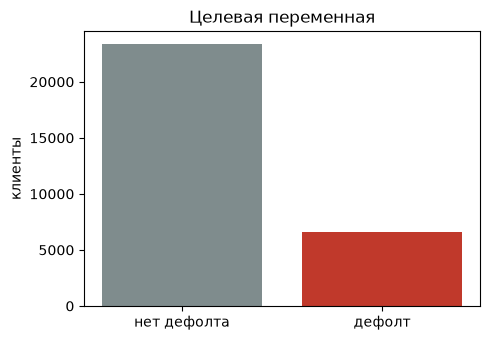

,count
default_payment_next_month,
0,23364
1,6636


In [2]:
counts = frame[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["нет дефолта", "дефолт"], counts.values, color=["#7f8c8d", "#c0392b"])
ax.set_ylabel("клиенты")
ax.set_title("Целевая переменная")
plt.tight_layout()
plt.show()
counts.to_frame("count")


## Демография

Коды исходного описания UCI:

- пол: 1 - мужчина, 2 - женщина;
- образование: 1 - аспирантура, 2 - университет, 3 - школа, остальные коды собраны в «другое»;
- брак: 1 - в браке, 2 - не в браке, остальные - «другое».


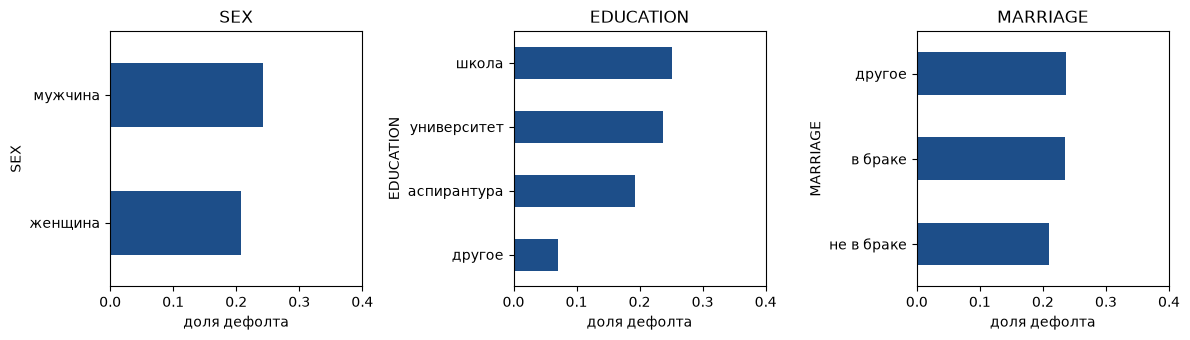

In [3]:
labels = {
    "SEX": {1: "мужчина", 2: "женщина"},
    "EDUCATION": {1: "аспирантура", 2: "университет", 3: "школа", 4: "другое"},
    "MARRIAGE": {1: "в браке", 2: "не в браке", 3: "другое"},
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, column in zip(axes, ("SEX", "EDUCATION", "MARRIAGE")):
    rates = frame.groupby(frame[column].map(labels[column]), observed=True)[TARGET].mean()
    rates.sort_values().plot(kind="barh", ax=ax, color="#1d4e89")
    ax.set_xlabel("доля дефолта")
    ax.set_title(column)
    ax.set_xlim(0, 0.4)
fig.tight_layout()
plt.show()


## Платежная история сильнее анкеты

`PAY_0` - статус самого свежего месяца: −2 и −1 означают отсутствие долга или оплату вовремя, 0 - возобновляемый кредит, положительные значения - число месяцев просрочки. `n_late_payments` считает, сколько из шести месяцев имели просрочку.


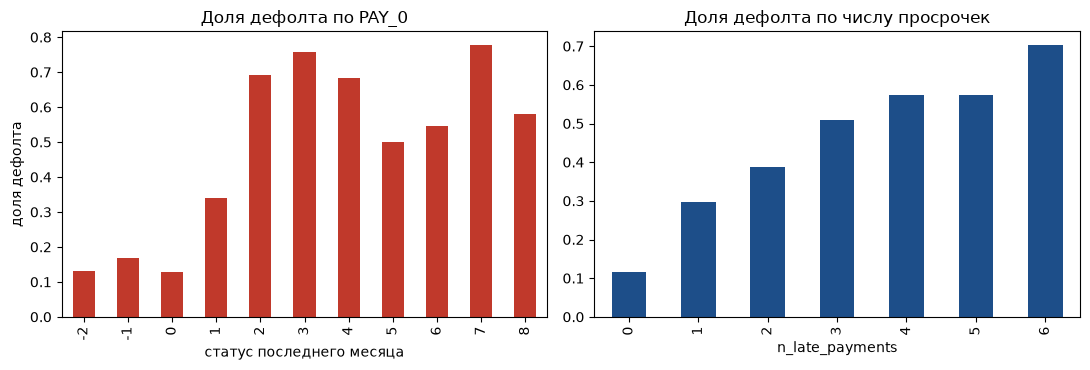

корреляция PAY_0 с дефолтом: 0.325
корреляция n_late_payments с дефолтом: 0.398
корреляция LIMIT_BAL с дефолтом: -0.154


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
pay = frame.groupby("PAY_0")[TARGET].mean()
pay.plot(kind="bar", ax=axes[0], color="#c0392b")
axes[0].set_title("Доля дефолта по PAY_0")
axes[0].set_ylabel("доля дефолта")
axes[0].set_xlabel("статус последнего месяца")

late = frame.groupby("n_late_payments")[TARGET].mean()
late.plot(kind="bar", ax=axes[1], color="#1d4e89")
axes[1].set_title("Доля дефолта по числу просрочек")
axes[1].set_xlabel("n_late_payments")
fig.tight_layout()
plt.show()
print("корреляция PAY_0 с дефолтом:", round(frame["PAY_0"].corr(frame[TARGET]), 3))
print("корреляция n_late_payments с дефолтом:", round(frame["n_late_payments"].corr(frame[TARGET]), 3))
print("корреляция LIMIT_BAL с дефолтом:", round(frame["LIMIT_BAL"].corr(frame[TARGET]), 3))


## Лимит и возраст

Меньший лимит чаще встречается среди дефолтов. Возраст сам по себе слабее: бин нужен скорее как устойчивая категория, чем как главный фактор.


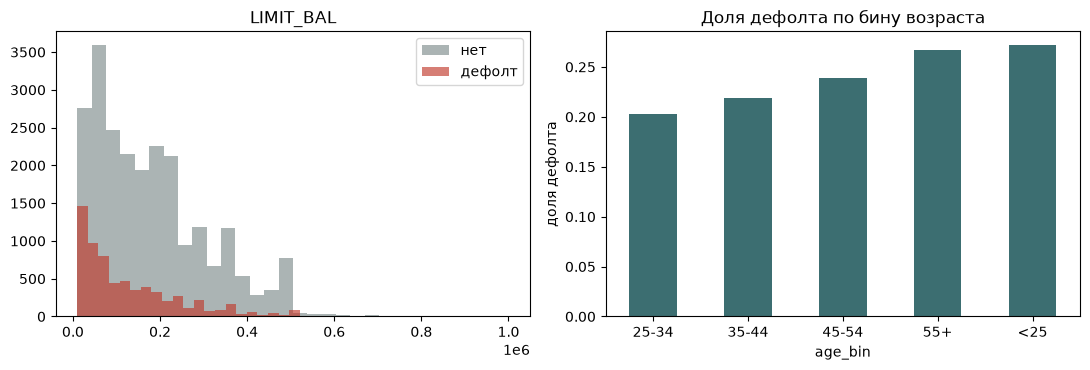

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for label, color, name in ((0, "#7f8c8d", "нет"), (1, "#c0392b", "дефолт")):
    subset = frame.loc[frame[TARGET] == label, "LIMIT_BAL"]
    axes[0].hist(subset, bins=30, alpha=0.65, color=color, label=name)
axes[0].set_title("LIMIT_BAL")
axes[0].legend()
frame.groupby("age_bin", observed=True)[TARGET].mean().plot(kind="bar", ax=axes[1], color="#3c6e71")
axes[1].set_title("Доля дефолта по бину возраста")
axes[1].set_ylabel("доля дефолта")
axes[1].tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## Выводы для модели

- Пропусков в сырых полях нет, но валидация Great Expectations все равно стоит на входе: новый батч может приехать битым.
- Классы несбалансированы (около 22% дефолтов), поэтому accuracy - плохая цель.
- Главный сигнал - недавняя просрочка и число просроченных месяцев. Лимит связан с риском слабее и в обратную сторону.
- Пол, образование и брак дают небольшие сдвиги доли дефолта. Их оставляем категориальными признаками, а не выбрасываем.
- В пайплайн обучения уходят и сырые суммы, и агрегаты истории: среднее/максимум статуса, утилизация лимита, отношение платежа к предыдущему счету.
